# Scorecard de riesgo de crédito — Documento de desarrollo y validación

**Modelo:** probabilidad de incumplimiento (PD) de un préstamo de consumo, expresada en
puntos.
**Datos:** 19 905 préstamos de LendingClub otorgados entre 2007 y 2011, ya terminados.
**Validación:** fuera de tiempo. El modelo se desarrolla con 2007–2010 y se prueba con 2011.

Este notebook sigue la estructura de un informe de validación de modelos de un banco:
objetivo y uso, datos, definición del evento, desarrollo, discriminación, calibración,
estabilidad, explicabilidad, punto de corte y limitaciones. Todas las cifras salen del
paquete `scorecard` (en `src/`); el notebook no reimplementa el entrenamiento.

In [1]:
import warnings

warnings.filterwarnings("ignore")

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from scorecard import metricas as m
from scorecard import pipeline as p
from scorecard import puntaje
from scorecard.datos import ETIQUETAS, EVENTO

pd.set_option("display.precision", 3)
pd.set_option("display.max_columns", 20)

# Estilo de los gráficos: marcas finas, ejes y grilla recesivos, un color por serie.
TINTA, TINTA_2, TENUE, GRILLA, EJE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
plt.rcParams.update(
    {
        "figure.facecolor": "#fcfcfb",
        "axes.facecolor": "#fcfcfb",
        "axes.edgecolor": EJE,
        "axes.labelcolor": TINTA_2,
        "text.color": TINTA,
        "xtick.color": TENUE,
        "ytick.color": TENUE,
        "axes.grid": True,
        "grid.color": GRILLA,
        "grid.linewidth": 0.6,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "lines.linewidth": 2,
        "font.size": 10,
        "axes.titlesize": 11,
        "axes.titleweight": "bold",
        "axes.titlelocation": "left",
        "legend.frameon": False,
        "figure.dpi": 110,
    }
)


def pct(serie):
    return serie.map(lambda v: f"{v:.1%}")


r = p.entrenar()
tr, va, oot = r.particion.entrenamiento, r.particion.validacion, r.particion.oot
comparacion = p.comparacion_modelos(r)

## 0. Resumen ejecutivo

In [3]:
fila = comparacion.query("clave == 'scorecard' and muestra == 'oot'").iloc[0]
pd_oot = r.pd("scorecard", oot)
psi, csi = p.estabilidad(r)
psi_oot = psi.loc[psi["muestra"] == p.OOT, "psi_puntaje"].iloc[0]
resumen = pd.DataFrame(
    {
        "Métrica (muestra fuera de tiempo, 2011)": [
            "AUC (IC 95%)",
            "Gini",
            "KS",
            "Brier",
            "PD promedio estimada",
            "Tasa de incumplimiento observada",
            "Error de calibración por decil",
            "PSI del puntaje (2007-2010 contra 2011)",
        ],
        "Valor": [
            f"{fila.auc:.3f} ({fila.auc_ic_inferior:.3f} - {fila.auc_ic_superior:.3f})",
            f"{fila.gini:.3f}",
            f"{fila.ks:.3f}",
            f"{fila.brier:.3f}",
            f"{fila.pd_promedio:.1%}",
            f"{fila.tasa_observada:.1%}",
            f"{m.error_calibracion(oot[EVENTO], pd_oot):.1%}",
            f"{psi_oot:.3f}",
        ],
    }
)
display(resumen.style.hide(axis="index"))

"Métrica (muestra fuera de tiempo, 2011)",Valor
AUC (IC 95%),0.691 (0.678 - 0.705)
Gini,0.382
KS,0.291
Brier,0.124
PD promedio estimada,14.6%
Tasa de incumplimiento observada,15.7%
Error de calibración por decil,1.3%
PSI del puntaje (2007-2010 contra 2011),0.042


**Conclusiones**

1. **Discrimina de forma moderada y supera a la calificación existente.** En 2011 el
   scorecard alcanza un AUC de 0,69 (Gini 0,38). La calificación de LendingClub sola
   llega a 0,66; la diferencia, +0,03, tiene un intervalo de 95% que no incluye el cero.
2. **Un modelo lineal basta.** LightGBM, con todas las variables, empata con el
   scorecard (diferencia de AUC 0,000) y la red neuronal queda por debajo. No hay
   ganancia que justifique perder interpretabilidad.
3. **Subestima el riesgo en 2011.** La PD promedio es 14,6% y la tasa observada 15,7%;
   la prueba de Hosmer-Lemeshow rechaza la calibración. Se recomienda recalibrar el
   intercepto antes de usar la PD para provisiones o precios.
4. **El puntaje es estable** (PSI 0,04), pero el plazo cambió de forma moderada: los
   préstamos a 60 meses pasaron de 16% a 33% de la cartera.

## 1. Objetivo y uso

**Para qué sirve.** Ordenar solicitudes de préstamo de consumo por su riesgo de
incumplimiento y apoyar una decisión de aprobación con un punto de corte. El usuario
previsto es una entidad que evalúa préstamos originados por LendingClub: conoce los datos
de la solicitud y la calificación que asigna LendingClub.

**Para qué no sirve.** No reemplaza un modelo con información de buró de crédito
(puntaje FICO, historial de pagos), que esta base no incluye. No está validado para otro
país ni otro producto. La PD sin recalibrar no debe usarse para provisiones.

**Evento.** Incumplimiento = el préstamo terminó castigado (*Charged Off*). Un préstamo
pagado por completo (*Fully Paid*) es bueno. La ventana de desempeño es la vida completa
del préstamo (36 o 60 meses).

## 2. Datos y población

filtro,prestamos
Base original,19908
Con estado final conocido (pagado o castigado),19905
Con fecha de emisión válida,19905


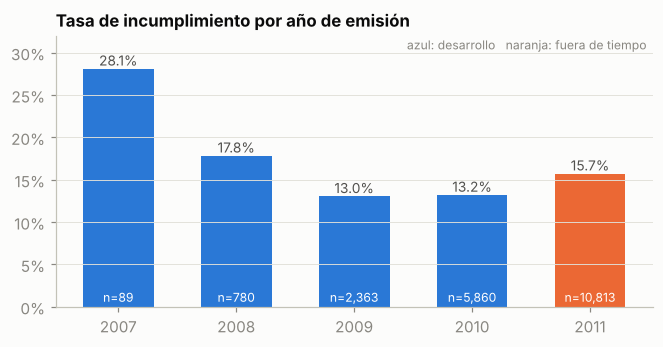

In [4]:
display(r.exclusiones.style.hide(axis="index"))

df = pd.concat([tr, va, oot])
por_anio = df.groupby("anio").agg(prestamos=(EVENTO, "size"), tasa=(EVENTO, "mean"))
fig, ax = plt.subplots(figsize=(7, 3.2))
colores = [SERIES[0] if a <= 2010 else SERIES[1] for a in por_anio.index]
ax.bar(por_anio.index.astype(str), por_anio["tasa"], color=colores, width=0.6)
for x, (n, t) in enumerate(zip(por_anio["prestamos"], por_anio["tasa"], strict=True)):
    ax.text(x, t + 0.004, f"{t:.1%}", ha="center", color=TINTA_2, fontsize=9)
    ax.text(x, 0.006, f"n={n:,}", ha="center", color="white", fontsize=8)
ax.set_title("Tasa de incumplimiento por año de emisión")
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_ylim(0, 0.32)
ax.grid(axis="x", visible=False)
ax.text(
    0.99,
    0.95,
    "azul: desarrollo   naranja: fuera de tiempo",
    transform=ax.transAxes,
    ha="right",
    color=TENUE,
    fontsize=8,
)
plt.show()

- La base es una muestra de préstamos de seis estados (CA, NY, FL, TX, NJ, IL). Solo
  incluye préstamos terminados, así que no hay préstamos vigentes que puedan sesgar la
  tasa de incumplimiento hacia abajo.
- 2007 tiene solo 89 préstamos; su tasa alta pesa poco en el desarrollo.
- Se eliminó la columna de cargo declarado (texto libre) y se corrigieron dos valores de
  uso de línea revolvente mayores que 150%, que son errores de captura.

## 3. Partición fuera de tiempo

El desarrollo usa los préstamos de 2007 a 2010, divididos al azar en entrenamiento (75%)
y validación (25%), estratificando por el evento. Los préstamos de 2011 no se tocan hasta
la prueba final: simulan aplicar el modelo a la cartera del año siguiente.

In [5]:
t = r.particion.resumen()
t["tasa_incumplimiento"] = pct(t["tasa_incumplimiento"])
display(t.style.hide(axis="index"))

parte,prestamos,incumplimientos,tasa_incumplimiento
Entrenamiento (2007-2010),6819,934,13.7%
Validación (2007-2010),2273,311,13.7%
Fuera de tiempo (2011),10813,1698,15.7%


## 4. Análisis univariado: WoE e Information Value

Cada variable se agrupa en tramos con la muestra de entrenamiento. En las numéricas, los
tramos tienen al menos 5% de la muestra y una tasa de incumplimiento monótona; en las
categóricas, las categorías con menos de 2% se agrupan en "OTRAS". El WoE de un tramo es
ln(% de buenos / % de malos): positivo significa menos riesgo que el promedio.

Lectura usual del IV: menos de 0,02 sin poder; 0,02 a 0,10 débil; 0,10 a 0,30 medio;
0,30 a 0,50 fuerte; más de 0,50, sospechoso de fuga de información.

etiqueta,iv,tramos,poder
Calificación de LendingClub,0.254,6,Medio
Plazo (meses),0.076,2,Débil
Propósito del préstamo,0.067,9,Débil
Ingreso anual (USD),0.053,6,Débil
Monto / ingreso anual,0.036,6,Débil
Estado de residencia,0.032,7,Débil
Uso de línea revolvente (%),0.028,6,Débil
Cuota anual / ingreso,0.028,6,Débil
Antigüedad laboral (años),0.017,5,Sin poder
Quiebras registradas,0.013,2,Sin poder


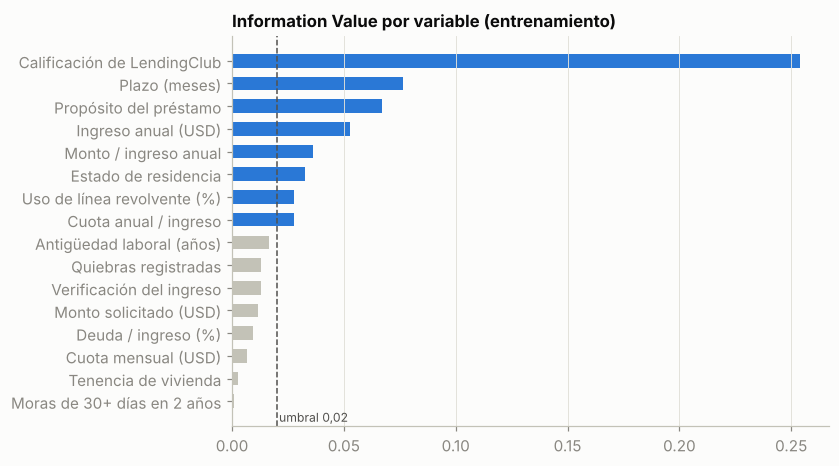

In [6]:
iv = r.agrupador.tabla_iv()
iv["etiqueta"] = iv["variable"].map(ETIQUETAS)
display(iv[["etiqueta", "iv", "tramos", "poder"]].style.hide(axis="index").format({"iv": "{:.3f}"}))

orden = iv.sort_values("iv")
fig, ax = plt.subplots(figsize=(7, 4.6))
color = [SERIES[0] if v >= 0.02 else EJE for v in orden["iv"]]
ax.barh(orden["etiqueta"], orden["iv"], color=color, height=0.6)
ax.axvline(0.02, color=TINTA_2, lw=1, ls="--")
ax.text(0.021, -0.9, "umbral 0,02", color=TINTA_2, fontsize=8)
ax.set_title("Information Value por variable (entrenamiento)")
ax.grid(axis="y", visible=False)
plt.show()

Con datos de la solicitud, el poder individual es bajo: ninguna variable pasa de 0,08
salvo la calificación de LendingClub (0,25). Es esperable: esta base no tiene historial
de buró, que es lo que más predice el incumplimiento en consumo. Ninguna variable supera
0,5, así que no hay señales de fuga de información.

Tramos de las variables que entran al modelo:

In [7]:
for v in r.scorecard.variables:
    t = r.agrupador.tramos[v].tabla.rename_axis("tramo").reset_index()
    t = t[["tramo", "n", "participacion", "tasa_incumplimiento", "woe", "iv"]]
    print(ETIQUETAS[v])
    display(
        t.style.hide(axis="index").format(
            {
                "n": "{:,.0f}",
                "participacion": "{:.1%}",
                "tasa_incumplimiento": "{:.1%}",
                "woe": "{:.3f}",
                "iv": "{:.4f}",
            }
        )
    )

Calificación de LendingClub


tramo,n,participacion,tasa_incumplimiento,woe,iv
A,"1,515",22.2%,5.5%,0.992,0.1517
B,"2,088",30.6%,13.0%,0.059,0.0010
C,"1,593",23.4%,13.9%,-0.019,0.0001
D,"1,007",14.8%,20.1%,-0.457,0.0363
E,437,6.4%,24.3%,-0.703,0.0403
OTRAS,179,2.6%,26.8%,-0.841,0.0247


Plazo (meses)


tramo,n,participacion,tasa_incumplimiento,woe,iv
<= 36,"5,712",83.8%,12.1%,0.138,0.0151
> 36,"1,107",16.2%,21.7%,-0.557,0.0612


Propósito del préstamo


tramo,n,participacion,tasa_incumplimiento,woe,iv
OTRAS,471,6.9%,16.1%,-0.194,0.0028
car,210,3.1%,11.0%,0.240,0.0016
credit_card,927,13.6%,9.9%,0.364,0.0158
debt_consolidation,"3,080",45.2%,13.7%,0.003,0.0000
home_improvement,406,6.0%,15.3%,-0.130,0.0011
major_purchase,401,5.9%,10.5%,0.299,0.0047
other,827,12.1%,13.8%,-0.007,0.0000
small_business,305,4.5%,26.6%,-0.823,0.0401
wedding,192,2.8%,11.5%,0.189,0.0009


Ingreso anual (USD)


tramo,n,participacion,tasa_incumplimiento,woe,iv
"<= 31,002",853,12.5%,19.7%,-0.435,0.0276
"(31,002, 41,000]",880,12.9%,16.7%,-0.234,0.0077
"(41,000, 50,000]",938,13.8%,13.8%,-0.005,0.0000
"(50,000, 69,996]","1,595",23.4%,12.4%,0.119,0.0032
"(69,996, 83,000]",857,12.6%,11.6%,0.193,0.0044
"> 83,000","1,696",24.9%,11.4%,0.206,0.0098


Estado de residencia


tramo,n,participacion,tasa_incumplimiento,woe,iv
CA,"2,442",35.8%,14.7%,-0.084,0.0026
FL,930,13.6%,17.3%,-0.276,0.0115
IL,507,7.4%,11.4%,0.202,0.0028
NJ,659,9.7%,14.7%,-0.085,0.0007
NY,"1,351",19.8%,11.1%,0.240,0.0104
TX,929,13.6%,11.6%,0.187,0.0044
Faltante,1,0.0%,0.0%,0.000,0.0000


## 5. Selección de variables y estimación

1. Se descartan las variables con IV menor que 0,02.
2. Entre pares con correlación de WoE mayor que 0,6 se conserva la de mayor IV.
3. Regresión logística sobre los WoE con eliminación hacia atrás: sale la variable con
   signo contrario al esperado (con esta convención de WoE, el coeficiente debe ser
   negativo) o, si no hay, la de p-valor mayor que 0,05.

La tasa de interés no es candidata: LendingClub la fija con su propio modelo de riesgo.
La calificación sí lo es, porque el usuario previsto la conoce al decidir.

In [8]:
display(r.scorecard.bitacora.style.hide(axis="index"))
display(r.scorecard.tabla_coeficientes().style.format("{:.3f}", na_rep=""))

variable,motivo
antiguedad_laboral,IV 0.017 menor que 0.02
quiebras,IV 0.013 menor que 0.02
verificacion_ingreso,IV 0.013 menor que 0.02
monto,IV 0.012 menor que 0.02
dti,IV 0.009 menor que 0.02
cuota,IV 0.007 menor que 0.02
vivienda,IV 0.003 menor que 0.02
moras_2_anios,IV 0.001 menor que 0.02
cuota_ingreso,"correlación 0.87 con monto_ingreso, que tiene más IV"
uso_linea_revolvente,signo contrario al esperado


,coeficiente,error_estandar,z,p_valor,vif
intercepto,-1.840,0.037,-49.709,0.000,
calificacion,-0.873,0.079,-10.992,0.000,1.078
plazo,-0.644,0.127,-5.059,0.000,1.065
proposito,-0.843,0.135,-6.220,0.000,1.014
ingreso_anual,-1.067,0.153,-6.961,0.000,1.004
estado,-0.933,0.201,-4.632,0.000,1.003


- **Uso de línea revolvente** sale por signo contrario: con la calificación en el modelo,
  su efecto se invierte, lo que sugiere que la calificación ya recoge esa información.
  Dejarla daría más puntos a quien usa más su línea, lo que no tiene sentido de negocio.
- **Monto / ingreso** sale por p-valor (0,38): el ingreso anual ya captura casi todo su
  aporte.
- Los VIF son cercanos a 1: no hay multicolinealidad entre las cinco variables finales.

## 6. Scorecard en puntos

Escala: 600 puntos equivalen a odds de 50 buenos por cada malo, y cada 20 puntos (PDO)
se duplican esas odds. Más puntos, menos riesgo. El puntaje de un préstamo es la suma de
los puntos de sus cinco tramos.

In [9]:
puntos = r.tabla_puntos.copy()
puntos["variable"] = puntos["variable"].map(ETIQUETAS)
display(
    puntos[["variable", "tramo", "n_entrenamiento", "tasa_incumplimiento", "puntos"]]
    .style.hide(axis="index")
    .format({"tasa_incumplimiento": "{:.1%}"})
)

variable,tramo,n_entrenamiento,tasa_incumplimiento,puntos
Calificación de LendingClub,A,1515,5.5%,133
Calificación de LendingClub,B,2088,13.0%,110
Calificación de LendingClub,C,1593,13.9%,108
Calificación de LendingClub,D,1007,20.1%,97
Calificación de LendingClub,E,437,24.3%,90
Calificación de LendingClub,OTRAS,179,26.8%,87
Plazo (meses),<= 36,5712,12.1%,111
Plazo (meses),> 36,1107,21.7%,98
Propósito del préstamo,OTRAS,471,16.1%,103
Propósito del préstamo,car,210,11.0%,114


## 7. Discriminación

Se compara el scorecard con:

- **Benchmark:** la calificación de LendingClub sola. Responde si el modelo agrega valor
  sobre lo que ya existe.
- **Scorecard sin calificación:** solo datos de la solicitud.
- **Retadores:** LightGBM y una red neuronal (1 capa de 16 neuronas, sigmoide), con
  todas las variables candidatas. Miden cuánto se pierde por usar un modelo lineal.

In [10]:
tabla = comparacion.pivot_table(index="modelo", columns="muestra", values="auc")
tabla = tabla[["entrenamiento", "validacion", "oot"]].sort_values("oot", ascending=False)
tabla.columns = ["AUC entrenamiento", "AUC validación", "AUC 2011"]
display(tabla.style.format("{:.3f}"))

dif = p.diferencias_oot(r)
display(
    dif.style.hide(axis="index").format(
        {
            "diferencia": "{:+.3f}",
            "ic_inferior": "{:+.3f}",
            "ic_superior": "{:+.3f}",
            "prob_mayor": "{:.0%}",
        }
    )
)

,AUC entrenamiento,AUC validación,AUC 2011
modelo,,,
Scorecard (logístico sobre WoE),0.679,0.678,0.691
Retador: LightGBM,0.745,0.678,0.691
Scorecard sin calificación,0.646,0.664,0.675
Retador: red neuronal,0.623,0.667,0.669
Benchmark: calificación de LendingClub,0.629,0.631,0.660


comparacion,diferencia,ic_inferior,ic_superior,prob_mayor
Scorecard menos Benchmark: calificación de LendingClub,+0.031,+0.022,+0.040,100%
Scorecard menos Scorecard sin calificación,+0.016,+0.008,+0.024,100%
Scorecard menos Retador: LightGBM,+0.000,-0.005,+0.005,53%
Scorecard menos Retador: red neuronal,+0.022,+0.012,+0.033,100%


- El scorecard supera al benchmark (+0,031, IC 95% de +0,021 a +0,040) y al modelo sin
  calificación (+0,016): la calificación y los datos de la solicitud se complementan.
- **LightGBM empata** (+0,000, IC de −0,005 a +0,005) y muestra sobreajuste: 0,745 en
  entrenamiento contra 0,678 en validación. El scorecard tiene el mismo AUC en
  entrenamiento y en validación.
- En todos los modelos el AUC de 2011 es algo mayor que el del desarrollo. La cartera de
  2011 tiene más préstamos a 60 meses, que son más riesgosos, y esa mezcla más
  heterogénea facilita ordenar. No es una mejora del modelo.

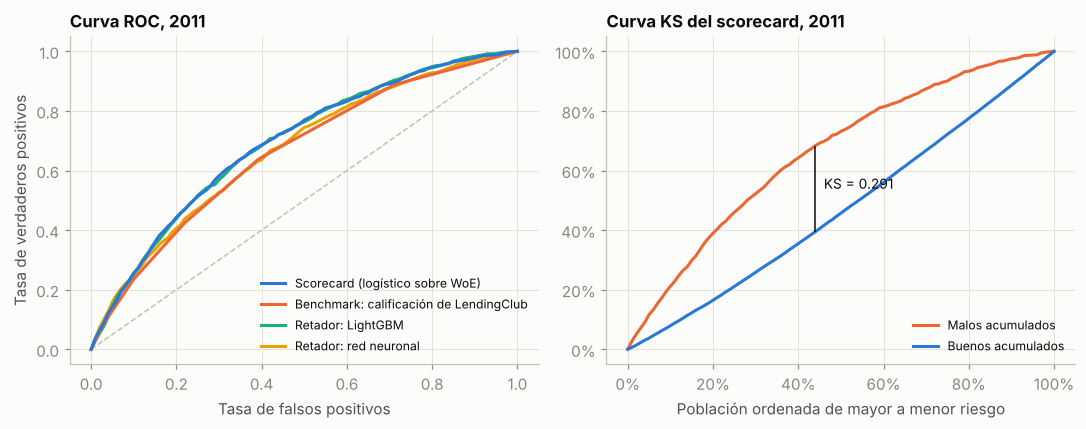

In [11]:
roc, ks = p.curvas(r)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 4))
for orden, (color, (nombre, g)) in enumerate(
    zip(SERIES, roc.groupby("modelo", sort=False), strict=True)
):
    # El scorecard (primera serie) va al frente para que no lo tape LightGBM.
    a1.plot(g["fpr"], g["tpr"], color=color, label=nombre, zorder=10 - orden)
a1.plot([0, 1], [0, 1], color=EJE, lw=1, ls="--")
a1.set(
    title="Curva ROC, 2011",
    xlabel="Tasa de falsos positivos",
    ylabel="Tasa de verdaderos positivos",
)
a1.legend(fontsize=8, loc="lower right")

g = ks[ks["modelo"] == p.NOMBRES["scorecard"]]
a2.plot(g["poblacion"], g["malos_acumulados"], color=SERIES[1], label="Malos acumulados")
a2.plot(g["poblacion"], g["buenos_acumulados"], color=SERIES[0], label="Buenos acumulados")
i = (g["malos_acumulados"] - g["buenos_acumulados"]).idxmax()
x, y1, y2 = g.loc[i, ["poblacion", "malos_acumulados", "buenos_acumulados"]]
a2.vlines(x, y2, y1, color=TINTA, lw=1)
a2.text(x + 0.02, (y1 + y2) / 2, f"KS = {m.ks(oot[EVENTO], pd_oot):.3f}", color=TINTA, fontsize=9)
a2.set(title="Curva KS del scorecard, 2011", xlabel="Población ordenada de mayor a menor riesgo")
a2.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
a2.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
a2.legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.show()

### Tabla de deciles (2011)

In [12]:
deciles = m.tabla_deciles(oot[EVENTO], pd_oot)
display(
    deciles.style.hide(axis="index").format(
        {
            "pd_promedio": "{:.1%}",
            "pd_minima": "{:.1%}",
            "pd_maxima": "{:.1%}",
            "tasa_observada": "{:.1%}",
            "captura_acumulada": "{:.1%}",
            "lift": "{:.2f}",
        }
    )
)

decil,n,malos,pd_promedio,pd_minima,pd_maxima,tasa_observada,captura_acumulada,lift
1,1082,357,33.1%,26.9%,63.3%,33.0%,21.0%,2.10
2,1081,305,24.1%,21.8%,26.9%,28.2%,39.0%,1.80
3,1081,223,19.5%,18.0%,21.8%,20.6%,52.1%,1.31
4,1081,206,16.4%,15.1%,18.0%,19.1%,64.3%,1.21
5,1082,151,13.7%,12.7%,15.1%,14.0%,73.1%,0.89
6,1081,141,11.8%,10.8%,12.7%,13.0%,81.4%,0.83
7,1081,101,9.8%,8.8%,10.8%,9.3%,87.4%,0.59
8,1081,100,7.8%,6.5%,8.8%,9.3%,93.3%,0.59
9,1081,72,5.7%,4.9%,6.5%,6.7%,97.5%,0.42
10,1082,42,4.0%,2.8%,4.9%,3.9%,100.0%,0.25


El 20% de mayor riesgo concentra 39% de los incumplimientos, y su tasa (31%) es más de
siete veces la del decil de menor riesgo (3,9%). La tasa observada baja de forma casi
monótona entre deciles.

## 8. Calibración

Una PD bien calibrada coincide con la tasa observada. Se mira por decil, con una prueba
binomial en cada decil y la prueba de Hosmer-Lemeshow para el conjunto.

muestra,pd_promedio,tasa_observada,error_por_decil,hosmer_lemeshow_p
Validación (2007-2010),13.6%,13.7%,1.9%,0.129
Fuera de tiempo (2011),14.6%,15.7%,1.3%,0.002


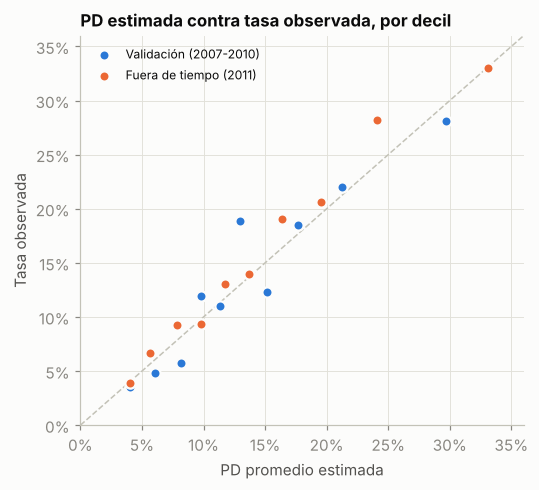

decil,n,malos,pd_promedio,tasa_observada,diferencia,p_valor_binomial
1,1082,357,33.1%,33.0%,-0.1%,0.974
2,1081,305,24.1%,28.2%,+4.1%,0.002
3,1081,223,19.5%,20.6%,+1.1%,0.357
4,1081,206,16.4%,19.1%,+2.7%,0.019
5,1082,151,13.7%,14.0%,+0.3%,0.791
6,1081,141,11.8%,13.0%,+1.3%,0.202
7,1081,101,9.8%,9.3%,-0.5%,0.646
8,1081,100,7.8%,9.3%,+1.4%,0.089
9,1081,72,5.7%,6.7%,+1.0%,0.147
10,1082,42,4.0%,3.9%,-0.1%,0.938


In [13]:
y_va, pd_va = va[EVENTO], r.pd("scorecard", va)
filas = []
for nombre, y, q in [
    ("Validación (2007-2010)", y_va, pd_va),
    ("Fuera de tiempo (2011)", oot[EVENTO], pd_oot),
]:
    hl = m.hosmer_lemeshow(y, q)
    filas.append(
        {
            "muestra": nombre,
            "pd_promedio": q.mean(),
            "tasa_observada": y.mean(),
            "error_por_decil": m.error_calibracion(y, q),
            "hosmer_lemeshow_p": hl["p_valor"],
        }
    )
display(
    pd.DataFrame(filas)
    .style.hide(axis="index")
    .format(
        {
            "pd_promedio": "{:.1%}",
            "tasa_observada": "{:.1%}",
            "error_por_decil": "{:.1%}",
            "hosmer_lemeshow_p": "{:.3f}",
        }
    )
)

cal_va = m.tabla_calibracion(y_va, pd_va)
cal_oot = m.tabla_calibracion(oot[EVENTO], pd_oot)
fig, ax = plt.subplots(figsize=(5.2, 4.6))
ax.plot([0, 0.4], [0, 0.4], color=EJE, lw=1, ls="--")
for tabla_cal, color, nombre in [
    (cal_va, SERIES[0], "Validación (2007-2010)"),
    (cal_oot, SERIES[1], "Fuera de tiempo (2011)"),
]:
    ax.scatter(
        tabla_cal["pd_promedio"],
        tabla_cal["tasa_observada"],
        s=45,
        color=color,
        label=nombre,
        zorder=3,
        edgecolor="#fcfcfb",
        lw=1.5,
    )
ax.set(
    title="PD estimada contra tasa observada, por decil",
    xlabel="PD promedio estimada",
    ylabel="Tasa observada",
    xlim=(0, 0.36),
    ylim=(0, 0.36),
)
ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.legend(fontsize=8, loc="upper left")
plt.show()

display(
    cal_oot.style.hide(axis="index").format(
        {
            "pd_promedio": "{:.1%}",
            "tasa_observada": "{:.1%}",
            "diferencia": "{:+.1%}",
            "p_valor_binomial": "{:.3f}",
        }
    )
)

- **En validación la calibración es buena:** Hosmer-Lemeshow no la rechaza.
- **En 2011 el modelo subestima:** casi todos los puntos naranjas quedan sobre la
  diagonal. La diferencia está en la tasa promedio (15,7% contra 13,7% en desarrollo),
  no en el orden. Es el patrón de un cambio en la mezcla de la cartera o en el entorno.

**Recalibración propuesta.** Se corrige solo el intercepto para que la PD promedio
coincida con la tasa reciente. Para no evaluarla con los mismos datos con que se estima,
el ajuste se calcula con 2011T1-T2 y se prueba con 2011T3-T4.

In [14]:
recal = p.recalibracion(r)
display(pd.Series(recal).to_frame("valor").style.format("{:.4f}"))

,valor
desplazamiento_intercepto,0.0316
tasa_observada_estimacion,0.1558
tasa_observada_evaluacion,0.1579
pd_promedio_antes,0.1413
pd_promedio_despues,0.1449
error_calibracion_antes,0.0180
error_calibracion_despues,0.0151
hosmer_lemeshow_p_antes,0.0014
hosmer_lemeshow_p_despues,0.0155


El ajuste acerca la PD promedio a la tasa observada y reduce el error por decil, pero la
tasa siguió subiendo en el segundo semestre (16,9% en el cuarto trimestre), así que no
cierra toda la brecha. En producción, el intercepto se recalibraría de forma periódica
con la tasa de incumplimiento más reciente.

## 9. Estabilidad

El PSI compara la distribución del puntaje en entrenamiento con la de otra muestra.
Lectura: menos de 0,10 estable; 0,10 a 0,25 cambio moderado; más de 0,25 cambio
importante. El CSI es el mismo cálculo sobre los tramos de cada variable.

In [15]:
display(psi.style.hide(axis="index").format({"psi_puntaje": "{:.3f}"}))
csi["variable"] = csi["variable"].map(ETIQUETAS)
display(csi.style.hide(axis="index").format({"csi_oot": "{:.3f}"}))

muestra,psi_puntaje,lectura
Validación (2007-2010),0.005,Estable
Fuera de tiempo (2011),0.042,Estable
2011Q1,0.072,Estable
2011Q2,0.071,Estable
2011Q3,0.040,Estable
2011Q4,0.022,Estable


variable,csi_oot,lectura
Calificación de LendingClub,0.033,Estable
Plazo (meses),0.160,Cambio moderado
Propósito del préstamo,0.022,Estable
Ingreso anual (USD),0.006,Estable
Estado de residencia,0.003,Estable


trimestre,prestamos,tasa_observada,pd_promedio,auc,ks,psi_puntaje,participacion_60_meses
2011Q1,2063,15.0%,14.9%,0.695,0.311,0.072,35.5%
2011Q2,2475,16.1%,15.4%,0.700,0.303,0.071,36.1%
2011Q3,2936,14.6%,14.1%,0.690,0.290,0.040,31.4%
2011Q4,3339,16.9%,14.2%,0.683,0.297,0.022,31.2%


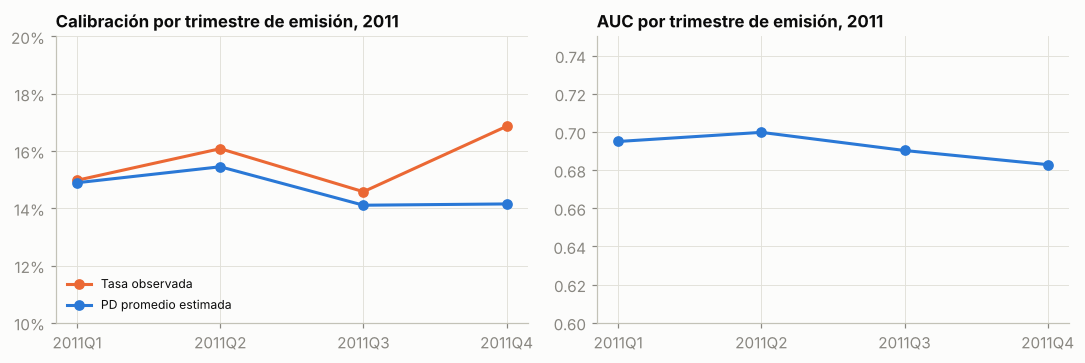

In [16]:
mon = p.monitoreo_trimestral(r)
display(
    mon.style.hide(axis="index").format(
        {
            "tasa_observada": "{:.1%}",
            "pd_promedio": "{:.1%}",
            "auc": "{:.3f}",
            "ks": "{:.3f}",
            "psi_puntaje": "{:.3f}",
            "participacion_60_meses": "{:.1%}",
        }
    )
)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.4))
x = mon["trimestre"]
a1.plot(x, mon["tasa_observada"], color=SERIES[1], marker="o", label="Tasa observada")
a1.plot(x, mon["pd_promedio"], color=SERIES[0], marker="o", label="PD promedio estimada")
a1.set(title="Calibración por trimestre de emisión, 2011", ylim=(0.10, 0.20))
a1.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
a1.legend(fontsize=8, loc="lower left")
a2.plot(x, mon["auc"], color=SERIES[0], marker="o")
a2.set(title="AUC por trimestre de emisión, 2011", ylim=(0.6, 0.75))
plt.tight_layout()
plt.show()

- El puntaje es estable en todos los trimestres (PSI máximo 0,07).
- **El plazo es la única variable con cambio moderado** (CSI 0,16): los préstamos a 60
  meses son 16% del entrenamiento y 33% de 2011. Explica parte de la subestimación, y es
  la primera variable que vigilar.
- El AUC se mantiene entre 0,68 y 0,70 en los cuatro trimestres.

## 10. Qué pesa en el modelo

Para el scorecard, el peso de cada variable es |coeficiente| × desviación estándar de su
WoE. Para LightGBM, el promedio del valor absoluto de SHAP en 2011. Ambos se normalizan
para sumar 100%.

In [17]:
imp = p.importancia(r)
imp["variable"] = imp["variable"].map(ETIQUETAS)
display(imp.style.hide(axis="index").format({"scorecard": "{:.1%}", "lightgbm_shap": "{:.1%}"}))

variable,scorecard,lightgbm_shap
Calificación de LendingClub,37.8%,28.6%
Ingreso anual (USD),19.0%,13.5%
Plazo (meses),13.2%,12.0%
Estado de residencia,13.5%,8.7%
Propósito del préstamo,16.5%,8.0%
Antigüedad laboral (años),0.0%,7.1%
Cuota mensual (USD),0.0%,3.2%
Uso de línea revolvente (%),0.0%,3.2%
Deuda / ingreso (%),0.0%,3.2%
Monto / ingreso anual,0.0%,3.0%


Los dos modelos coinciden en lo principal: la calificación es la variable que más pesa,
seguida del ingreso, el plazo, el propósito y el estado. LightGBM reparte el resto entre
variables que, por separado, casi no tienen poder (antigüedad laboral, cuota, uso de
línea). Ese reparto no mejora su AUC fuera de tiempo, lo que indica que el scorecard no
deja fuera señal relevante.

## 11. Punto de corte

Se aprueba si el puntaje es mayor o igual que el corte. La tabla muestra el costo y el
beneficio de cada corte en 2011.

corte,tasa_aprobacion,incumplimiento_aprobados,incumplimiento_rechazados,malos_evitados,buenos_rechazados
510,95.9%,14.8%,35.8%,9.4%,3.1%
515,91.8%,14.0%,34.3%,17.8%,6.4%
520,87.0%,13.2%,32.2%,26.6%,10.4%
525,80.1%,12.1%,30.3%,38.4%,16.5%
530,74.7%,11.3%,28.8%,46.3%,21.3%
535,65.9%,10.1%,26.6%,57.7%,29.7%
540,57.9%,9.1%,24.8%,66.5%,37.5%
545,47.6%,8.2%,22.5%,75.2%,48.1%
550,38.0%,7.3%,20.8%,82.3%,58.3%
555,30.6%,6.7%,19.7%,87.0%,66.2%


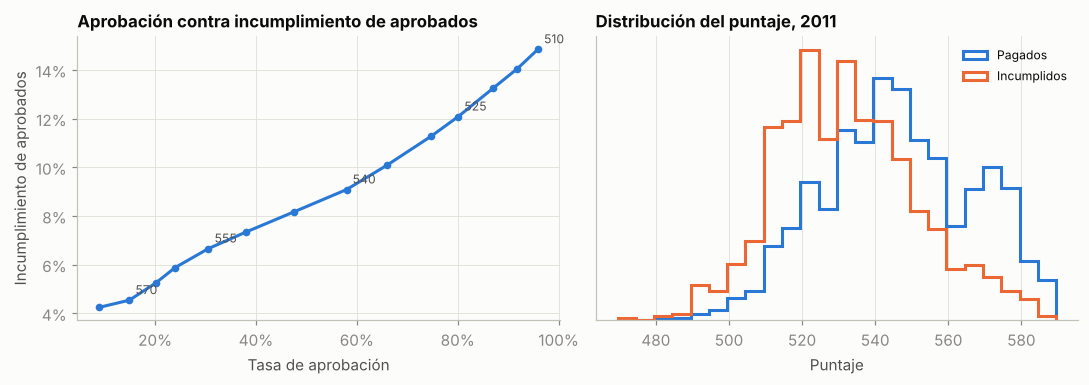

In [18]:
puntaje_oot = r.puntaje(oot)
cortes = puntaje.tabla_cortes(oot[EVENTO], puntaje_oot)
display(
    cortes.style.hide(axis="index").format(
        {
            "tasa_aprobacion": "{:.1%}",
            "incumplimiento_aprobados": "{:.1%}",
            "incumplimiento_rechazados": "{:.1%}",
            "malos_evitados": "{:.1%}",
            "buenos_rechazados": "{:.1%}",
        }
    )
)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.6))
a1.plot(
    cortes["tasa_aprobacion"],
    cortes["incumplimiento_aprobados"],
    color=SERIES[0],
    marker="o",
    markersize=4,
)
for _, f in cortes.iloc[::3].iterrows():
    a1.annotate(
        f"{f.corte:.0f}",
        (f.tasa_aprobacion, f.incumplimiento_aprobados),
        textcoords="offset points",
        xytext=(4, 4),
        fontsize=8,
        color=TINTA_2,
    )
a1.set(
    title="Aprobación contra incumplimiento de aprobados",
    xlabel="Tasa de aprobación",
    ylabel="Incumplimiento de aprobados",
)
a1.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
a1.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")

bordes = np.arange(puntaje_oot.min() - 2.5, puntaje_oot.max() + 5, 5)
a2.hist(
    puntaje_oot[oot[EVENTO] == 0],
    bins=bordes,
    density=True,
    histtype="step",
    color=SERIES[0],
    lw=2,
    label="Pagados",
)
a2.hist(
    puntaje_oot[oot[EVENTO] == 1],
    bins=bordes,
    density=True,
    histtype="step",
    color=SERIES[1],
    lw=2,
    label="Incumplidos",
)
a2.set(title="Distribución del puntaje, 2011", xlabel="Puntaje")
a2.legend(fontsize=8)
a2.grid(axis="y", visible=False)
a2.set_yticks([])
plt.tight_layout()
plt.show()

Por ejemplo, un corte de 530 puntos aprueba 75% de las solicitudes de 2011, baja el
incumplimiento de los aprobados de 15,7% a 11,3% y evita 46% de los malos, a costa de
rechazar 21% de los buenos. El corte final depende de la rentabilidad de cada préstamo y
de la pérdida dado el incumplimiento, que esta base no permite estimar.

## 12. Limitaciones y plan de monitoreo

**Limitaciones**

1. **Sin información de buró.** La base no tiene puntaje FICO ni historial de pagos; la
   calificación de LendingClub es su único reflejo. Por eso la discriminación es moderada.
2. **Subestimación en 2011.** La PD requiere recalibrar el intercepto antes de usarse en
   provisiones o precios.
3. **Una sola ventana de prueba (2011).** No se sabe cómo se comporta el modelo en otro
   momento del ciclo económico.
4. **Muestra parcial.** Seis estados y 19 905 préstamos, no la cartera completa de
   LendingClub.
5. **Solo préstamos aprobados.** No se conoce el desempeño de las solicitudes rechazadas
   (sesgo de selección); no se aplicó inferencia de rechazados.
6. **Sin pérdida dada el incumplimiento.** El punto de corte se analiza en tasas, no en
   montos.

**Monitoreo propuesto**

| Indicador | Frecuencia | Alerta | Acción |
|---|---|---|---|
| PSI del puntaje | Mensual | Mayor que 0,10 | Revisar la mezcla de la cartera |
| CSI del plazo | Mensual | Mayor que 0,25 | Evaluar reajustar los tramos |
| Tasa observada contra PD promedio | Trimestral | Diferencia mayor que 2 puntos | Recalibrar el intercepto |
| AUC y KS | Trimestral | AUC menor que 0,65 | Revisar el modelo completo |

## 13. Cómo reproducir

```bash
pip install -e ".[dev,notebooks]"
python -m scorecard.pipeline      # entrena, valida y guarda artefactos/
pytest                            # pruebas unitarias y con la base real
jupyter nbconvert --to notebook --execute --inplace notebooks/01_desarrollo_y_validacion.ipynb
```